# Calculus of variations 1: Shortest paths and the fastest slide

*Learning path: calculus of variations, part 1 of 3.* [Index](README.md) · Next: [Hanging chains and soap films](02-hanging-chains-and-soap-films.ipynb)

In June 1696 Johann Bernoulli challenged "the sharpest mathematicians in the world" with a puzzle. A bead slides
without friction along a wire from a point A down to a lower point B, not straight below it. Which shape of wire
gets it there fastest? The straight line is the shortest, but not the fastest: a steeper start builds up speed
early. Isaac Newton is said to have received the problem one afternoon and solved it overnight. Leibniz, Jakob
Bernoulli and l'Hôpital solved it too.

Ordinary calculus finds the *number* $x$ that makes a function $f(x)$ smallest. The **calculus of variations** finds the
*function* $y(x)$, a whole curve, that makes a quantity such as a length, a time or an energy smallest. Leonhard Euler
and Joseph-Louis Lagrange turned the puzzle-solving of the Bernoullis into a method in the 1750s. It is the language
of mechanics, optics, relativity and optimal control.

**Who this is for.** Students who know derivatives and integrals; the
[differential equations](../differential-equations/README.md) path helps.

**What you will be able to do afterwards:**

1. compute a functional (a length, a travel time) along a given path with `action`;
2. derive and use the Euler–Lagrange equation with `eulerlagrange`;
3. find an optimal path numerically with `extremal`;
4. use the conserved quantity `energy` to solve the fastest-slide problem;
5. explain why the fastest path is a cycloid, and why it may dip below its end point.

Plan about 50 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Functionals: numbers from whole paths

A path from $(0, 0)$ to $(1, 1)$ is a function $y(x)$ with $y(0) = 0$ and $y(1) = 1$. Its length is

$$J[y] = \int_0^1 \sqrt{1 + y'^2}\, dx.$$

$J$ takes a whole function and returns a number: it is a **functional**, and the expression inside the integral,
$L(x, y, y') = \sqrt{1 + y'^2}$, is its **Lagrangian**. `action(L, y, x, f, a, b)` computes $J$ along the path
$y = f(x)$. In $L$, write $y'$ for the derivative. Three paths:

In [1]:
action(sqrt(1 + d(y, x)^2), y, x, x, 0, 1)
eval(action(sqrt(1 + d(y, x)^2), y, x, x^2, 0, 1), 6)
eval(action(sqrt(1 + d(y, x)^2), y, x, sin(pi*x/2), 0, 1), 6)

sqrt(2)

> The integral of L = sqrt(d(y, x)^2+1) from x = 0 to 1 along the given path.

1.47894

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.46370

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

No surprise: the straight line, $\sqrt 2 \approx 1.414$, is the shortest. The question is how to *prove* that, and
how to find the best path when the answer is not obvious.

**Try this.** Compute the length of $y = x^3$ from $(0, 0)$ to $(1, 1)$. Which of the four paths is the longest?

## 2. The Euler–Lagrange equation

Suppose $y(x)$ is the best path. Bend it a little: $y + \varepsilon\,\eta(x)$, with $\eta = 0$ at both ends so the
end points stay put. As a function of the number $\varepsilon$, $J$ is smallest at $\varepsilon = 0$, so its
derivative there is 0:

$$0 = \int_a^b \Big( \frac{\partial L}{\partial y}\,\eta + \frac{\partial L}{\partial y'}\,\eta' \Big)\, dx
     = \int_a^b \Big( \frac{\partial L}{\partial y} - \frac{d}{dx}\frac{\partial L}{\partial y'} \Big)\, \eta\, dx,$$

after integrating the second term by parts. This holds for *every* bend $\eta$, so the bracket itself must be 0:

$$\frac{d}{dx}\frac{\partial L}{\partial y'} = \frac{\partial L}{\partial y}.$$

That is the **Euler–Lagrange equation**, a differential equation for the best path. `eulerlagrange(L, y, x)`
derives it, and solves it for $y''$ when it can. For the length:

In [2]:
eulerlagrange(sqrt(1 + d(y, x)^2), y, x)

d(y, x, 2) == 0

> Euler–Lagrange equation: d/dx(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain y itself, so dL/dy' = d(y, x)/sqrt(d(y, x)^2+1) stays constant along every extremal (a conserved momentum). L does not contain x itself, so energy(L, ...) = -1/sqrt(d(y, x)^2+1) stays constant along every extremal (Beltrami's identity, conservation of energy).

$y'' = 0$: the shortest paths are the straight lines, $y = C_1 + C_2 x$:

In [3]:
dsolve(d(y, x, 2) == 0, y, x)

C1+C2*x

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The note also says that $\partial L/\partial y' = y'/\sqrt{1 + y'^2}$ stays constant along the best path. That is
because $L$ does not contain $y$ itself: whenever a variable is missing from $L$, something is conserved. This
observation grows into Noether's theorem in lesson 3.

**Try this.** On a map where travelling costs $1/y$ per unit length (slow near the line $y = 0$), the cost of a path is
$\int \sqrt{1 + y'^2}\,/\,y\; dx$. Derive its Euler–Lagrange equation. (Its solutions are semicircles centred on the
line $y = 0$: the "straight lines" of the hyperbolic plane.)

## 3. The fastest slide

Measure $y$ **downwards** from the starting point. A bead that has fallen a height $y$ has speed $v = \sqrt{2 g y}$
(energy conservation, $\tfrac12 m v^2 = m g y$). A piece of wire of length $ds = \sqrt{1 + y'^2}\,dx$ takes time
$ds/v$, so the total time is

$$T[y] = \int_0^{x_B} \sqrt{\frac{1 + y'^2}{2 g\, y}}\; dx.$$

Take $g = 9.81$ and B at $(\pi, 2)$ metres. Compare a straight wire with two that start steeper:

In [4]:
eval(action(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, 2*x/pi, 0, pi), 4)
eval(action(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, 2*sqrt(x/pi), 0, pi), 4)
eval(action(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, 2*(x/pi)^(1/3), 0, pi), 4)

1.189

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.013

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.016

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The steeper starts win by about 15%. But which wire is best? `extremal(L, y, x, a, b, ya, yb)` finds it numerically:
it cuts the path into 100 straight pieces and lowers the total time with Newton's method:

In [5]:
s = extremal(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, 0, pi, 0, 2);
eval(s.J, 4)

1.003

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

About 1.003 seconds, faster than all three guesses. Here is the shape (drawn the right way up, so $-y$), together with
the **cycloid**: the curve traced by a point on the rim of a rolling wheel of radius 1,
$x = \theta - \sin\theta$, $y = 1 - \cos\theta$:

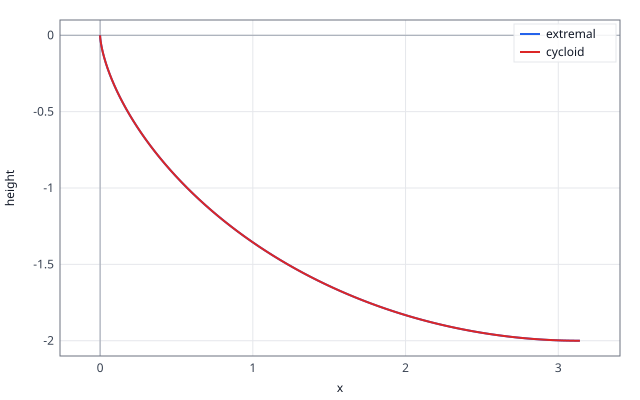

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
X = s.x;
Y = s.y;
p = legend(plot(X, -Y), "extremal");
p = show(p, legend(parametric(th - sin(th), cos(th) - 1, th, 0, pi), "cycloid"));
labels(p, "x", "height")

They lie on top of each other. The fastest slide is an upside-down cycloid, and the time along it is
$\pi\sqrt{r/g}$ for a wheel of radius $r$:

In [7]:
eval(pi/sqrt(9.81), 4)

1.003

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** Put B at $(1, 1)$. How long does the straight wire take, and how long the fastest one?

## 4. Why a cycloid: a conserved quantity

The Euler–Lagrange equation for the slide is a non-linear second-order equation:

In [8]:
eulerlagrange(sqrt((1 + d(y, x)^2)/y), y, x)

d(y, x, 2) == -(d(y, x)^2+1)/(2*y)

> Euler–Lagrange equation: d/dx(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain x itself, so energy(L, ...) = -1/(y*sqrt((d(y, x)^2+1)/y)) stays constant along every extremal (Beltrami's identity, conservation of energy).

(The constant $2g$ makes no difference to the best shape, so we leave it out.) Its note points to a shortcut. $L$ does
not contain $x$, and then the quantity

$$E = y'\,\frac{\partial L}{\partial y'} - L$$

is constant along the best path (**Beltrami's identity**; in mechanics it is the energy). `energy` computes it:

In [9]:
energy(sqrt((1 + d(y, x)^2)/y), y, x)

-1/(y*sqrt((d(y, x)^2+1)/y))

> E = y' dL/dy' - L, the sum of q' dL/dq' over the unknowns minus L. When L does not contain x itself, E is constant along every solution of the Euler–Lagrange equations: in mechanics it is the total energy, in geometry Beltrami's first integral.

So $-1/\sqrt{y\,(1 + y'^2)}$ is constant, which means $y\,(1 + y'^2) = k$ for some constant $k$: a first-order
equation. Johann Bernoulli recognised it from optics: light in a medium where its speed is $\sqrt{y}$ bends in the
same way (Snell's law), and the solution is a cycloid. Check it: on the cycloid $y = 1 - \cos\theta$, the slope is
$y' = \sin\theta/(1 - \cos\theta)$, and

In [10]:
simplify((1 - cos(th))*(1 + (sin(th)/(1 - cos(th)))^2))

2

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

a constant, 2, for every $\theta$.

**Try this.** Use `energy(sqrt(1 + d(y, x)^2), y, x)` for the length. Why does a constant value of it give straight lines
again?

## 5. Going down to come up

Now put B far to the side and only a little lower: at $(2\pi, 1)$.

1.594

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.873

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.17

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

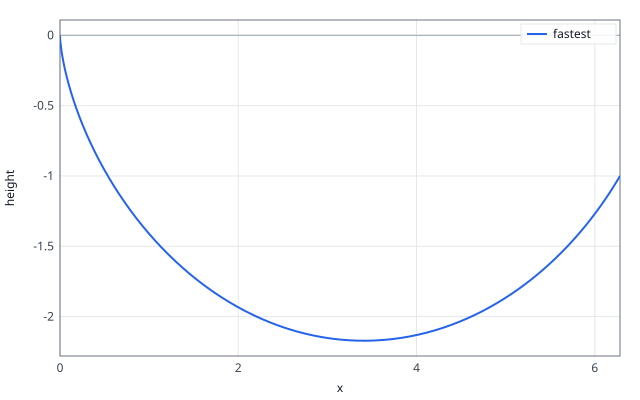

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
s = extremal(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, 0, 2*pi, 0, 1);
eval(s.J, 4)
eval(action(sqrt((1 + d(y, x)^2)/(2*9.81*y)), y, x, x/(2*pi), 0, 2*pi), 4)
Y = s.y;
eval(max(Y), 3)
labels(legend(plot(s.x, -Y), "fastest"), "x", "height")

The fastest wire first drops more than 2 metres, *below* B, and then climbs back up to it. Diving deep buys so much
speed that the bead wins the time back. It is still a cycloid, now a longer arc of a slightly bigger wheel, past its
lowest point. The straight wire takes almost twice as long.

The cycloid has a second surprise, found by Christiaan Huygens in 1659: a bead released from rest *anywhere* on an
upside-down cycloid reaches the bottom in the same time, $\pi\sqrt{r/g}$. Huygens used it to build a pendulum clock
whose period does not depend on the swing (the **tautochrone**).

**Try this.** Where along the way does the fastest wire to $(2\pi, 1)$ reach its lowest point? Look at the plot, then
compare with the cycloid: the lowest point is at $\theta = \pi$, $x = \pi r$, with $r \approx 1.086$.

## Summary

* A functional $J[y] = \int L(x, y, y')\,dx$ gives a number for each path; `action` computes it.
* The best path satisfies the Euler–Lagrange equation $\frac{d}{dx}\frac{\partial L}{\partial y'} = \frac{\partial L}{\partial y}$;
  `eulerlagrange` derives it.
* If $L$ does not contain $y$, then $\partial L/\partial y'$ is conserved; if it does not contain $x$, then
  `energy` $= y' L_{y'} - L$ is conserved.
* `extremal` finds the best path numerically between fixed end points.
* The fastest slide is a cycloid, and it may dip below its end point.

Next: [hanging chains and soap films](02-hanging-chains-and-soap-films.ipynb).

## Exercises

1. **Lengths.** Find the Euler–Lagrange equation of $L = \sqrt{1 + y'^2}$ and of $L = y'^2$. Do the two functionals
   have the same best paths?
2. **A wavy guess.** Compute the slide time to $(\pi, 2)$ along $y = 2x/\pi + \tfrac12\sin(x)$. Is it faster than
   the straight wire? Than the cycloid?
3. **Hyperbolic distance.** In the hyperbolic plane the length is $\int \sqrt{1 + y'^2}\,/\,y\,dx$. Compute the length of
   the semicircle $y = \sqrt{1 - x^2}$ from $x = -1/2$ to $x = 1/2$, and compare it with $\ln 3$.
4. **Light in a layer.** Light travels at speed $v(y)$; the travel time is $\int \sqrt{1 + y'^2}\,/\,v(y)\,dx$. For
   $v = 1 + y$ use `energy` to find a conserved quantity, and explain it as Snell's law $\sin(\text{angle})/v =$
   constant.
5. **Steeper is not always better.** Compute the slide time to $(\pi, 2)$ along $y = 2(x/\pi)^{1/10}$, which starts
   almost vertically. Why is it slower than the cycloid?

## Hints and answers

* **Section 1, Try this.** $1.548$, the longest of the four.
* **Section 2, Try this.** $y'' = -(1 + y'^2)/y$.
* **Section 3, Try this.** Straight: $0.639$ s; fastest: $0.583$ s.
* **Section 4, Try this.** $-1/\sqrt{1 + y'^2}$ constant means $y'$ is constant: a straight line.
* **Section 5, Try this.** Near $x \approx 3.44$ on the plot, against $\pi r \approx 3.41$ for the cycloid, at depth
  $2r \approx 2.17$.
* **Exercise 1.** Both give $y'' = 0$: the same straight lines (for $y'^2$ the note says $2y'$ is conserved).
* **Exercise 2.** About $1.055$ s: faster than straight ($1.189$), slower than the cycloid ($1.003$).
* **Exercise 3.** $1.0986 = \ln 3$.
* **Exercise 4.** `energy(sqrt(1 + d(y, x)^2)/(1 + y), y, x)` gives $-1/((1 + y)\sqrt{1 + y'^2})$. Since
  $1/\sqrt{1 + y'^2}$ is the sine of the angle between the ray and the vertical, $\sin(\text{angle})/v$ is constant.
* **Exercise 5.** About $1.067$ s. The bead gains speed early but then spends a long time on an almost flat stretch.

## Sources

1. J. Bernoulli, "Problema novum ad cujus solutionem mathematici invitantur", *Acta Eruditorum* (June 1696), 269.
2. L. Euler, *Methodus inveniendi lineas curvas maximi minimive proprietate gaudentes*, Bousquet, Lausanne (1744).
3. J.-L. Lagrange, letter to Euler of 12 August 1755, in *Œuvres de Lagrange*, vol. 14, Gauthier-Villars (1892).
4. C. Huygens, *Horologium oscillatorium*, Muguet, Paris (1673) (the tautochrone).
5. I. M. Gelfand and S. V. Fomin, *Calculus of Variations*, Prentice-Hall (1963), chapter 1.